In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from google.colab import files

uploaded = files.upload()

Saving data.csv to data.csv


In [4]:
df = pd.read_csv("data.csv")

print("First 5 rows:")
display(df.head())

print("Dataset shape:")
print(df.shape)

print("Column information:")
df.info()

First 5 rows:


,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0


Dataset shape:
(32, 5)
Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB


In [5]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

Total missing values:
3


In [8]:
# Reload the original dataset
df = pd.read_csv("data.csv")

# Fill missing Calories values with the
df["Calories"] = df["Calories"].fillna(df["Calories"].median())

# Remove the row where Date is missing
df = df.dropna(subset=["Date"])

# Verify missing values are handled
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nUpdated dataset shape:", df.shape)

Missing values after cleaning:
Duration    0
Date        0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64

Updated dataset shape: (31, 5)


In [9]:
# COunt duplicate rows
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Verify duplicates are removed
print("Duplicates after cleaning:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Duplicates before cleaning: 1
Duplicates after cleaning: 0
Dataset shape: (30, 5)


In [10]:
# Filter rows where Pulse is greater than 110
high_pulse = df[df["Pulse"]>110]

print("Reached where Pulse is greater than 110:")
display(high_pulse)

print("Number of matching records:",len(high_pulse))

Reached where Pulse is greater than 110:


,Duration,Date,Pulse,Maxpulse,Calories
1,60,'2020/12/02',117,145,479.0
4,45,'2020/12/05',117,148,406.0
23,60,'2020/12/23',130,101,300.0


Number of matching records: 3


In [12]:
# Create a new column
df["Pulse_Difference"] = df["Maxpulse"] - df["Pulse"]

# Display the updated dataset
display(df.head())

print("Updated column:")
print(df.columns.tolist())

,Duration,Date,Pulse,Maxpulse,Calories,Pulse_Difference
0,60,'2020/12/01',110,130,409.1,20
1,60,'2020/12/02',117,145,479.0,28
2,60,'2020/12/03',103,135,340.0,32
3,45,'2020/12/04',109,175,282.4,66
4,45,'2020/12/05',117,148,406.0,31


Updated column:
['Duration', 'Date', 'Pulse', 'Maxpulse', 'Calories', 'Pulse_Difference']


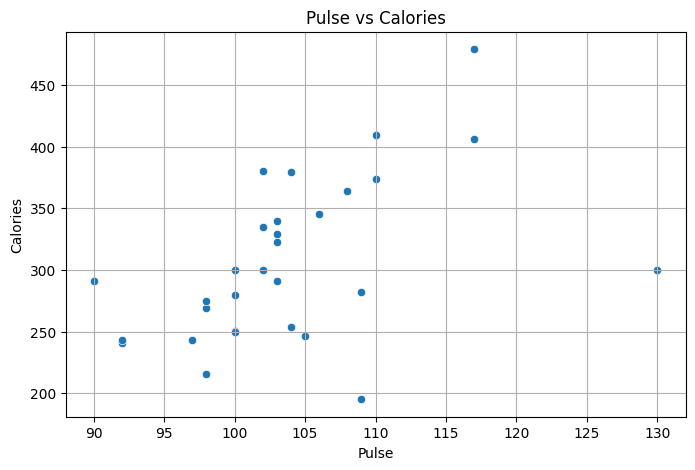

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Pulse", y="Calories")

plt.title("Pulse vs Calories")
plt.xlabel("Pulse")
plt.ylabel("Calories")
plt.grid(True)

plt.show()

In [14]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFinal columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Final dataset shape: (30, 6)

Missing values:
Duration            0
Date                0
Pulse               0
Maxpulse            0
Calories            0
Pulse_Difference    0
dtype: int64

Duplicate rows: 0

Final columns:
['Duration', 'Date', 'Pulse', 'Maxpulse', 'Calories', 'Pulse_Difference']

First 5 rows:


,Duration,Date,Pulse,Maxpulse,Calories,Pulse_Difference
0,60,'2020/12/01',110,130,409.1,20
1,60,'2020/12/02',117,145,479.0,28
2,60,'2020/12/03',103,135,340.0,32
3,45,'2020/12/04',109,175,282.4,66
4,45,'2020/12/05',117,148,406.0,31
